In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

In [2]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

if os.getcwd().split('/')[-1] == 'genjoin':
    os.chdir('../../')
os.getcwd()

'/home/claude/development/GraphQueryML'

In [3]:
import os
import pandas as pd
import numpy as np
import scipy
import seaborn as sns
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from matplotlib.legend_handler import HandlerTuple
from matplotlib.colors import LinearSegmentedColormap, to_rgba_array
from matplotlib.ticker import LogLocator
# from functools import partial
# from collections import defaultdict
from src.utils.path_helper import WORKLOADS
# from sklearn.neighbors import KNeighborsRegressor
# from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
# import json

In [4]:
# df_ho_stack = pd.read_csv('../QueryOptDeepDive/experiment_logs/postgres_v16/2024_10_28__HybridQO__STACK.csv')
# df_ho_job = pd.read_csv('../QueryOptDeepDive/experiment_logs/postgres_v16/2024_10_28__HybridQO__JOB.csv')
# df_as = pd.read_csv('../QueryOptDeepDive/experiment_logs/postgres_v16/2024_10_28__AutoSteer__JOB_STACK.csv')
# df_other = pd.concat([df_ho_stack, df_ho_job, df_as]).reset_index(drop=True)
# df_other.to_csv('data/processed/2024_10_28__HybridQO_AutoSteer__JOB_STACK.csv', index=False)

### Load HybridQO/AutoSteer and GenJoin

In [5]:
df_other = pd.read_csv('data/processed/2024_10_28__HybridQO_AutoSteer__JOB_STACK.csv')
df_other = df_other[df_other['split'] == 'test']
df_other.groupby(['method', 'workload']).count()

run_id  experiment  query_ident  \
method               workload                                                
AutoSteer            join_order_benchmark    1080        1080         1080   
                     stack                   1050        1050         1050   
HybridQO             join_order_benchmark    1080        1080         1080   
                     stack                   1050        1050         1050   
PostgreSQL_AutoSteer join_order_benchmark    1080        1080         1080   
                     stack                   1050        1050         1050   
PostgreSQL_HybridQO  join_order_benchmark    1080        1080         1080   
                     stack                   1050        1050         1050   

                                           split  inference_time  \
method               workload                                      
AutoSteer            join_order_benchmark   1080            1080   
                     stack                  1050            1050   
HybridQO             join_order_benchmark   1080            1080   
                     stack                  1050            1050   
PostgreSQL_AutoSteer join_order_benchmark   1080            1080   
                     stack                  1050            1050   
PostgreSQL_HybridQO  join_order_benchmark   1080            1080   
                     stack                  1050            1050   

                                           planning_time  execution_time  \
method               workload                                              
AutoSteer            join_order_benchmark           1080            1080   
                     stack                          1050            1050   
HybridQO             join_order_benchmark           1080            1080   
                     stack                          1050            1050   
PostgreSQL_AutoSteer join_order_benchmark           1080            1080   
                     stack                          1050            1050   
PostgreSQL_HybridQO  join_order_benchmark           1080            1080   
                     stack                          1050            1050   

                                           conf_pred  out_pred  
method               workload                                   
AutoSteer            join_order_benchmark          0         0  
                     stack                         0         0  
HybridQO             join_order_benchmark          0         0  
                     stack                         0         0  
PostgreSQL_AutoSteer join_order_benchmark          0         0  
                     stack                         0         0  
PostgreSQL_HybridQO  join_order_benchmark          0         0  
                     stack                         0         0

In [6]:
df_gj_job = pd.read_csv(f"data/processed/{WORKLOADS['join_order_benchmark']}/full_execution_time_test.csv")
df_gj_job['workload'] = 'join_order_benchmark'

df_gj_stack = pd.read_csv(f"data/processed/{WORKLOADS['stack']}/full_execution_time_test.csv")
df_gj_stack['workload'] = 'stack'

df_gj = pd.concat([df_gj_job, df_gj_stack])

# rename values in 'method' column
df_gj['method'] = df_gj['method'].apply(lambda x: 'PostgreSQL_GenJoin' if x == 'PostgreSQL' else x)
df_gj['method'] = df_gj['method'].apply(lambda x: 'GenJoin' if x == 'cVAE' else x)

df_gj.groupby(['method', 'workload']).count()

run_id  experiment  query_ident  \
method             workload                                                
GenJoin            join_order_benchmark    1479        1479         1479   
                   stack                   1272        1272         1272   
PostgreSQL_GenJoin join_order_benchmark    1419        1080         1419   
                   stack                   1389        1050         1389   

                                         split  inference_time  planning_time  \
method             workload                                                     
GenJoin            join_order_benchmark   1479            1479           1479   
                   stack                  1272            1272           1272   
PostgreSQL_GenJoin join_order_benchmark   1080            1419           1419   
                   stack                  1050            1389           1389   

                                         execution_time  conf_pred  out_pred  \
method             workload                                                    
GenJoin            join_order_benchmark            1479       1479      1479   
                   stack                           1272       1272      1272   
PostgreSQL_GenJoin join_order_benchmark            1419          0         0   
                   stack                           1389          0         0   

                                         shot  
method             workload                    
GenJoin            join_order_benchmark  1479  
                   stack                 1269  
PostgreSQL_GenJoin join_order_benchmark     0  
                   stack                    0

### Preprocessing

In [7]:
EXECUTION_TIME_OUT = 2 * 3 * 60 * 1000
experiments = [
    'base_query_split_a', 'base_query_split_b', 'base_query_split_c',
    'leave_one_out_split_a', 'leave_one_out_split_b', 'leave_one_out_split_c',
    'random_split_a', 'random_split_b', 'random_split_c',
    'slow_split'
]

df = pd.concat([df_other, df_gj])
# display(df.groupby(['method', 'workload']).count())


# merge all PostgreSQL together
df['method'] = df['method'].apply(lambda x: 'PostgreSQL' if x == 'PostgreSQL_GenJoin' else x)
df['method'] = df['method'].apply(lambda x: 'PostgreSQL' if x == 'PostgreSQL_AutoSteer' else x)
df['method'] = df['method'].apply(lambda x: 'PostgreSQL' if x == 'PostgreSQL_HybridQO' else x)


df.dropna(subset=['experiment'], inplace=True)  # using it to drop PostgreSQL outside of live runs

# Drop duplicates in cases there were issues with overwritting the results
df.drop_duplicates(subset=['method', 'run_id', 'experiment', 'query_ident', 'split'], 
                   keep='last', inplace=True)

df['run_type'] = 'regular'
df['timed_out'] = df['execution_time'] > EXECUTION_TIME_OUT
df['total_time'] = df['inference_time'] + df['planning_time'] + df['execution_time']
df['total_no_inference'] = df['planning_time'] + df['execution_time']
df['prepare_time'] = df['inference_time'] + df['planning_time']
df['base_experiment'] = df['experiment'].apply(lambda x: x.split('split')[0][:-1])  # NB! There should be a name `split` in experiment name


# convert from milliseconds to seconds
df['execution_time'] = df['execution_time'] / 1000
df['inference_time'] = df['inference_time'] / 1000
df['planning_time'] = df['planning_time'] / 1000
df['total_time'] = df['total_time'] / 1000
df['total_no_inference'] = df['total_no_inference'] / 1000
df['prepare_time'] = df['prepare_time'] / 1000



# Dropping duplicates for measurements on the base experiment level
df = df.sort_values(by=['total_time'], ascending=False).drop_duplicates(subset=['method', 'run_id', 'query_ident', 'base_experiment']).reset_index(drop=True)
# display(df.groupby(['workload', 'method', 'base_experiment']).count())

### Applying exponential weighting

In [8]:
# for workload in df['workload'].unique():
#     for method in df['method'].unique():
#         if 'PostgreSQL' in method:
#             continue
#         for base_experiment in df['base_experiment'].unique():
#             for run_id in df['run_id'].unique():
#                 df_tmp = df[
#                     (df['workload'] == workload) &
#                     (df['method'].isin([method, f'PostgreSQL_{method}'])) &
#                     (df['base_experiment'] == base_experiment) &
#                     (df['run_id'] == run_id)
#                 ]
#                 if df_tmp.shape[0] == 0:
#                     continue

#                 pg_data = df_tmp[df_tmp['method'] == f'PostgreSQL_{method}']
#                 method_data = df_tmp[df_tmp['method'] == method]

#                 for weighted_attr in ['total_time', 'execution_time']:
#                     pg_max = pg_data[weighted_attr].max()
#                     pg_min = pg_data[weighted_attr].min()
#                     pg_sumexp = np.sum(np.exp((pg_data[weighted_attr] - pg_min) / (pg_max - pg_min)))

#                     for query_ident in df_tmp['query_ident'].unique():
#                         pg_query = pg_data[pg_data['query_ident'] == query_ident].iloc[0]
#                         method_query = method_data[method_data['query_ident'] == query_ident].iloc[0]

#                         df.loc[method_query.name, f'{weighted_attr}__weighted'] = (np.exp((pg_query[weighted_attr] - pg_min) / (pg_max - pg_min)) / pg_sumexp) * method_query[weighted_attr] / pg_query[weighted_attr]
#                         df.loc[pg_query.name, f'{weighted_attr}__weighted'] = (((np.exp((pg_query[weighted_attr] - pg_min) / (pg_max - pg_min)) / pg_sumexp)))    


### Create aggregated dataframe
Iterate over all experiments ('split types') and aggregate the numbers across the various runs. Then make the same for PostgreSQL and copy each PostgreSQL run for all these split types, such that the train/test split is applied to make further comparisons easier (even though of course PostgreSQL is not trained in any capacity).

In [9]:
aggregated_dfs = []

for (workload, method, base_experiment), df_group in df.groupby(['workload', 'method', 'base_experiment']):
    df_group.loc[df_group.index, 'timed_out'] = df_group.loc[df_group.index, 'timed_out'].astype(int)

    x = df_group.groupby(['method', 'base_experiment', 'query_ident', 'split'], dropna=False)
    aggregated = x.agg({
        'total_no_inference': ['mean', 'std'],
        'inference_time': ['mean', 'std'],
        'planning_time': ['mean', 'std'],
        'execution_time': ['mean', 'std'],
        # 'execution_time__weighted': ['mean', 'std'],
        'total_time': ['mean', 'std'],
        # 'total_time__weighted': ['mean', 'std'],
        'prepare_time': ['mean', 'std'],
        'timed_out': 'max',
        'out_pred': 'mean',
        'conf_pred': 'mean'
    }).reset_index()

    # fix nested names from double aggregations
    new_col_names = []
    for c in aggregated.columns:
        if c[1] == 'std':
            new_col_names.append(".".join(c))
        else:
            new_col_names.append(c[0])
    aggregated.columns = new_col_names

    aggregated = aggregated.sort_values(['query_ident'])
    
    # correction for partial timed out queries across the same query_ident
    aggregated.loc[aggregated['timed_out'] > 0, 'timed_out'] = 1.0
    aggregated.loc[aggregated['timed_out'] > 0, 'execution_time'] = EXECUTION_TIME_OUT
    aggregated['total_time'] = aggregated['inference_time'] + aggregated['planning_time'] + aggregated['execution_time']
    aggregated['total_no_inference'] = aggregated['planning_time'] + aggregated['execution_time']

    # Add number of runs per query
    aggregated['n'] = x.count()['run_id'].tolist()
    aggregated['workload'] = workload

    aggregated_dfs.append(aggregated.copy())
    
df_agg = pd.concat(aggregated_dfs)
df_agg['total_time.var'] = df_agg['total_time.std'].apply(lambda x: x**2)
# df_agg['total_time__weighted.var'] = df_agg['total_time__weighted.std'].apply(lambda x: x**2)
df_agg['execution_time.var'] = df_agg['execution_time.std'].apply(lambda x: x**2)
# df_agg['execution_time__weighted.var'] = df_agg['execution_time__weighted.std'].apply(lambda x: x**2)
df_agg['total_no_inference.var'] = df_agg['total_no_inference.std'].apply(lambda x: x**2)
df_agg['counter'] = 1

# display(df_agg)

### Calculate result table values

In [10]:
df_sum = df_agg \
    .groupby(['base_experiment', 'workload', 'method', 'split']) \
    .agg({
        'total_time': 'sum',
        'total_no_inference': 'sum',
        # 'total_time__weighted': 'sum',
        'execution_time': 'sum',
        # 'execution_time__weighted': 'sum',
        'planning_time': 'sum',
        'inference_time': 'sum',
        'prepare_time': 'sum',
        'total_time.std': 'sum',
        # 'total_time__weighted.std': 'sum',
        'execution_time.std': 'sum',
        # 'execution_time__weighted.std': 'sum',
        'planning_time.std': 'sum',
        'inference_time.std': 'sum',
        'prepare_time.std': 'sum',
        'n': 'mean',
        'total_time.var': 'sum',
        'total_no_inference.var': 'sum',
        # 'total_time__weighted.var': 'sum',
        'execution_time.var': 'sum',
        # 'execution_time__weighted.var': 'sum',
        'counter': 'count'
    }) \
    .reset_index()

# for (workload, base_experiment), df_group in df_sum.groupby(['workload', 'base_experiment']):
#     print(workload, base_experiment)
#     # for col in sorted(df_group.columns):
#     #     print(col)
#     display(df_group[['base_experiment', 'workload', 'method', 'total_time', 'total_no_inference']])

df_sum.iloc[:8]

,base_experiment,workload,method,split,total_time,total_no_inference,execution_time,planning_time,inference_time,prepare_time,total_time.std,execution_time.std,planning_time.std,inference_time.std,prepare_time.std,n,total_time.var,total_no_inference.var,execution_time.var,counter
0,base_query,join_order_benchmark,AutoSteer,test,2500.728333,228.529667,224.110333,4.419333,2272.198667,2276.618000,142.651003,105.626644,3.910416,42.560608,45.408483,3.0,3672.055965,3540.711662,3534.608152,113
1,base_query,join_order_benchmark,GenJoin,test,130.837333,106.372485,103.140501,3.231984,24.464848,27.696832,2.424780,2.426127,0.029712,0.000000,0.029712,3.0,0.437712,0.437712,0.437925,113
2,base_query,join_order_benchmark,HybridQO,test,217.479139,180.671228,178.300029,2.371200,36.807911,39.179111,43.442211,41.977383,0.109683,2.085465,2.114002,3.0,763.063924,763.420382,762.717036,113
3,base_query,join_order_benchmark,PostgreSQL,test,155.478086,155.478086,152.255570,3.222516,0.000000,3.222516,2.834501,2.832688,0.037236,0.000000,0.037236,3.0,0.535983,0.535983,0.536297,147
4,base_query,stack,AutoSteer,test,2904.566667,83.687667,77.197667,6.490000,2820.879000,2827.369000,88.250443,19.078757,1.727399,72.871735,73.035465,3.0,1299.647696,18.717251,18.493302,112
5,base_query,stack,GenJoin,test,98.286719,75.606940,67.836145,7.770795,22.679779,30.450574,1.698412,1.692704,0.031432,0.000044,0.031475,3.0,0.446011,0.446010,0.445412,112
6,base_query,stack,HybridQO,test,102.124989,79.508764,72.486157,7.022607,22.616225,29.638832,5.682500,4.268945,0.212984,2.046531,2.104915,3.0,2.027638,1.778879,1.779106,112
7,base_query,stack,PostgreSQL,test,82.004984,82.004984,74.253014,7.751970,0.000000,7.751970,1.831043,1.829759,0.031081,0.000000,0.031081,3.0,0.945842,0.945842,0.945898,112


## Generate Figures

In [11]:
def get_base_experiments(slow=False):
    if slow:
        return ['slow'][::-1]
    return ['leave_one_out', 'random', 'base_query'][::-1]

def get_exeriment_labels(slow=False):
    if slow:
        return ['Slow\nSplit'][::-1]
    return ['Leave One Out\nSplit', 'Random\nSplit', 'Base Query\nSplit'][::-1]

def get_experiment_labels__short(slow=False):
    if slow:
        return ['SL'][::-1]
    return ['LOO', 'RND', 'BQ'][::-1]

WORKLOADS = {
    'stack': 'STACK',
    'join_order_benchmark': 'JOB'
}

STACK: 0.856 [s] +- 1.246 [s] (min: 0.020 [s], max: 5.942 [s])
Percentage of queries below 1s: 29.11%
JOB: 1.203 [s] +- 2.113 [s] (min: 0.008 [s], max: 14.458 [s])
Percentage of queries below 1s: 18.39%


Text(0, 0.5, 'Ratio of Queries with that Execution Time')

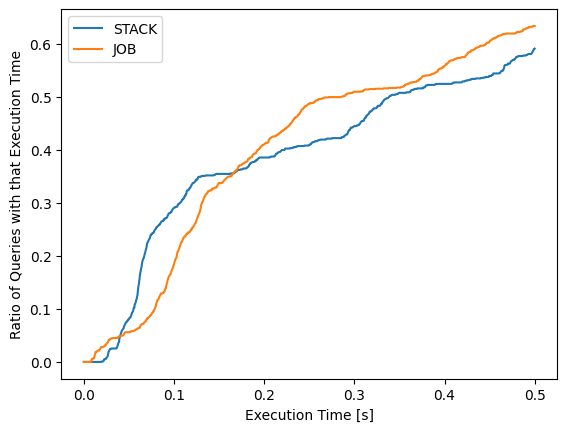

In [12]:
pg_stack = df[(df['workload'] == 'stack') & (df['method'] == 'PostgreSQL')]['total_no_inference']
pg_job = df[(df['workload'] == 'join_order_benchmark') & (df['method'] == 'PostgreSQL')]['total_no_inference']

# plt.hist(pg_stack, alpha=0.4, label='STACK')
# plt.hist(pg_job, alpha=0.4, label='JOB')
# plt.legend()

plt.figure()

secs = np.arange(0, 1001) / 2000

for lbl, x in [('STACK', pg_stack), ('JOB', pg_job)]:
    print(f"{lbl}: {x.mean():.3f} [s] +- {x.std():.3f} [s] (min: {x.min():.3f} [s], max: {x.max():.3f} [s])")
    print(f"Percentage of queries below 1s: {100 * ((x < 0.1).sum() / x.shape[0]):.2f}%")
    
    px = []
    for sec in secs:
        px.append((x <= sec).sum() / x.shape[0])

    plt.plot(secs, px, label=lbl)
    
plt.legend()
plt.xlabel('Execution Time [s]')
plt.ylabel('Ratio of Queries with that Execution Time')


JOB: Min: 0.0086 Max: 14.1796 Mean: 1.0345 Std: 1.9212
STACK: Min: 0.0245 Max: 5.7243 Mean: 0.7446 Std: 1.1245


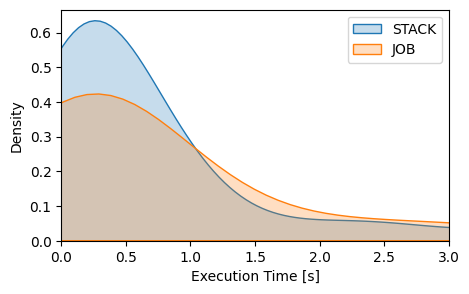

In [68]:
import seaborn as sns

pg_stack = df[(df['workload'] == 'stack') & (df['method'] == 'PostgreSQL')].groupby('query_ident')['total_no_inference'].mean()
pg_job = df[(df['workload'] == 'join_order_benchmark') & (df['method'] == 'PostgreSQL')].groupby('query_ident')['total_no_inference'].mean()

print(f"JOB: Min: {pg_job.min():.4f} Max: {pg_job.max():.4f} Mean: {pg_job.mean():.4f} Std: {pg_job.std():.4f}")
print(f"STACK: Min: {pg_stack.min():.4f} Max: {pg_stack.max():.4f} Mean: {pg_stack.mean():.4f} Std: {pg_stack.std():.4f}")

plt.figure(figsize=(5,3))

sns.kdeplot(pg_stack, label='STACK', fill=True)
sns.kdeplot(pg_job, label='JOB', fill=True)

plt.xlabel('Execution Time [s]')
plt.xlim(0, 3)
# plt.xlim(left=0)
plt.legend()

plt.savefig(f"figures/fig__execution_time_pdf.png", bbox_inches='tight')
plt.show()

In [22]:
def _get_method_data(method, workload, do_slow=False):
    df_method = df_sum[(df_sum['method'] == method) & (df_sum['workload'] == workload)]
    if do_slow:
        df_method = df_method[df_method['base_experiment'] == 'slow']
    else:
        df_method = df_method[df_method['base_experiment'] != 'slow']
    return df_method

def get_method_data_with_differences(method, workload, time_attribute, do_slow=False):
    df_pg = _get_method_data('PostgreSQL', workload, do_slow=do_slow)
    df_method = _get_method_data(method, workload, do_slow=do_slow)

    df_method[f'{time_attribute}.diff'] = df_pg[f'{time_attribute}'].values - df_method[f'{time_attribute}'].values
    df_method[f'{time_attribute}.total_var'] = np.sqrt(df_pg[f'{time_attribute}.var'].values / df_pg['n'].values + df_method[f'{time_attribute}.var'].values / df_method['n'].values)
    df_method['t_value'] = df_method[f'{time_attribute}.diff'].apply(lambda x: scipy.stats.t.ppf(q=0.05, df=3+3-2) if x < 0 else scipy.stats.t.ppf(q=1-0.05, df=3+3-2))
    df_method[f'{time_attribute}.ci'] = df_method[f'{time_attribute}.total_var'] * df_method['t_value']
    return df_method

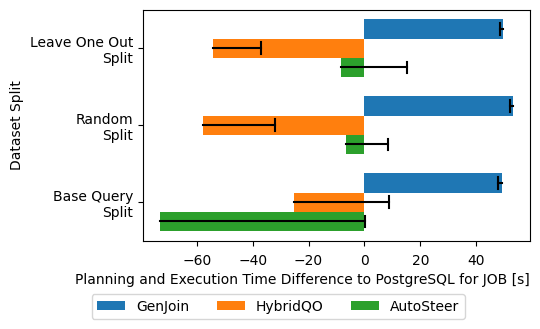

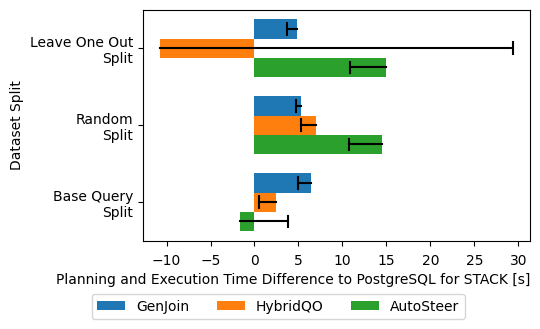

In [120]:
def plot_relative_difference_figure(methods, workload, do_inference=False, do_slow=False, min_x=None, max_x=None):
    base_experiments = get_base_experiments(slow=do_slow)
    experiment_labels = get_exeriment_labels(slow=do_slow)
    plot_colors = np.array(list(mcolors.TABLEAU_COLORS.keys()))
    bar_height = (1/(len(methods)+1))
    time_attribute = 'total_time' if do_inference else 'total_no_inference'

    fig, ax = plt.subplots(figsize=(5, 3))

    execution_handles = []
    for mi, method in enumerate(methods):
        df_method = get_method_data_with_differences(method, workload, time_attribute, do_slow=do_slow)

        bar_pos = np.arange(len(base_experiments)) + ((len(methods)/2) * bar_height) - (mi * bar_height) - bar_height
        bar_color = plot_colors[mi]

        execution_data = np.array([df_method.loc[df_method['base_experiment']==e,f'{time_attribute}.diff'].item() for e in base_experiments])
        execution_ci = np.array([df_method.loc[df_method['base_experiment']==e,f'{time_attribute}.ci'].item() for e in base_experiments])

        # COMMENT HERE: fake one-sided error bars
        ax.plot([execution_data-execution_ci, execution_data], [bar_pos + bar_height/2, bar_pos + bar_height/2], color='black')
        ax.plot([execution_data-execution_ci, execution_data-execution_ci], [bar_pos+0.05, bar_pos + bar_height-0.05], color='black')

        barh = ax.barh(bar_pos, execution_data, capsize=5, height=(1/(len(methods)+1)), align='edge', color=bar_color, label=method)

        # COMMENT HERE: original error bars
        # xerr = np.concatenate([
        #     [x if x >= 0 else 0 for x in execution_ci ],
        #     [np.abs(x) if x < 0 else 0 for x in execution_ci ]
        # ]).reshape(2, -1)
        # barh = ax.barh(bar_pos, execution_data, xerr=xerr, capsize=5, height=(1/(len(methods)+1)), align='edge', color=bar_color, label=method)

        execution_handles.append(barh)

    ax.set_yticklabels(experiment_labels)
    ax.set_yticks(np.array(bar_pos) + bar_height * len(methods)/2)
    ax.tick_params(axis='x', pad=5.8)


    if max_x is None:
        max_x = np.max(ax.get_xlim())
    if min_x is None:
        min_x = np.min(ax.get_xlim())
    ax.set_xlim([min_x, max_x])


    ax.set_ylim([-0.5, len(base_experiments)-0.5])

    ax.set_ylabel('Dataset Split')

    if do_inference:
        execution_time_label = 'End-to-End Execution Time'
    else:
        execution_time_label = 'Planning and Execution Time'
    ax.set_xlabel(f'{execution_time_label} Difference to PostgreSQL for {WORKLOADS[workload]} [s]', loc='right')

    ax.legend(execution_handles, methods, bbox_to_anchor=(0.35, -0.2), ncol=3, loc='upper center')

    plt.subplots_adjust(wspace=.6)
    # plt.title(f"Execution Time Difference for '{WORKLOADS[workload]}' Workload\n(With{'' if do_inference else 'out'} Inference Time)")
    plt.savefig(f"figures/fig__{workload}_{'inference' if do_inference else 'no_inference'}{'_slow' if do_slow else ''}.png", bbox_inches='tight')
    plt.show()
    

plot_relative_difference_figure(['GenJoin', 'HybridQO', 'AutoSteer'], 'join_order_benchmark', do_inference=False)
plot_relative_difference_figure(['GenJoin', 'HybridQO', 'AutoSteer'], 'stack', do_inference=False)

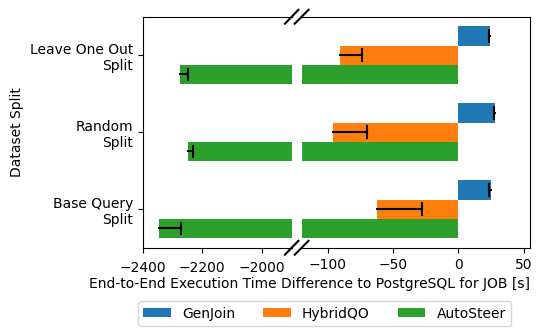

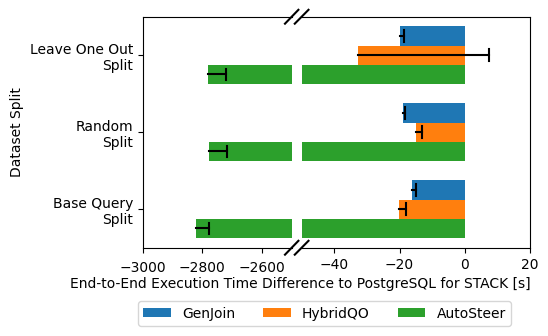

In [119]:
def plot_relative_difference_figure__x_axis_split(methods, workload, do_inference=False, do_slow=False, min_x=None, max_x=None, left_x_min=None, left_x_max=None):
    base_experiments = get_base_experiments(slow=do_slow)
    experiment_labels = get_exeriment_labels(slow=do_slow)
    plot_colors = np.array(list(mcolors.TABLEAU_COLORS.keys()))
    bar_height = (1/(len(methods)+1))
    time_attribute = 'total_time' if do_inference else 'total_no_inference'

    plt.figure(figsize=(5, 3))
    ax_left = plt.subplot2grid((1, 15), (0, 0), colspan=6, rowspan=1)
    ax_right = plt.subplot2grid((1, 15), (0, 6), colspan=9, rowspan=1) 

    execution_handles = []
    for mi, method in enumerate(methods):
        df_method = get_method_data_with_differences(method, workload, time_attribute, do_slow=do_slow)

        bar_pos = np.arange(len(base_experiments)) + ((len(methods)/2) * bar_height) - (mi * bar_height) - bar_height
        bar_color = plot_colors[mi]

        execution_data = np.array([df_method.loc[df_method['base_experiment']==e,f'{time_attribute}.diff'].item() for e in base_experiments])
        execution_ci = np.array([df_method.loc[df_method['base_experiment']==e,f'{time_attribute}.ci'].item() for e in base_experiments])

        ax_left.plot([execution_data-execution_ci, execution_data], [bar_pos + bar_height/2, bar_pos + bar_height/2], color='black')
        ax_left.plot([execution_data-execution_ci, execution_data-execution_ci], [bar_pos+0.05, bar_pos + bar_height-0.05], color='black')
        ax_right.plot([execution_data-execution_ci, execution_data], [bar_pos + bar_height/2, bar_pos + bar_height/2], color='black')
        ax_right.plot([execution_data-execution_ci, execution_data-execution_ci], [bar_pos+0.05, bar_pos + bar_height-0.05], color='black')

        barh = ax_left.barh(bar_pos, execution_data, capsize=5, height=(1/(len(methods)+1)), align='edge', color=bar_color, label=method)
        _ = ax_right.barh(bar_pos, execution_data, capsize=5, height=(1/(len(methods)+1)), align='edge', color=bar_color, label=method)
        execution_handles.append(barh)

        # if mi == 0:
        #     display(df_pg[['workload', 'method', 'base_experiment', 'total_time', 'total_no_inference', 'planning_time', 'execution_time', 'inference_time']])
        # display(df_method[['workload', 'method', 'base_experiment', f'{time_attribute}', f'{time_attribute}.ci', 'planning_time', 'execution_time', 'inference_time']])

        # display(df_method[['base_experiment', 'method', 'split', 'total_time', 'total_time__weighted', 'inference_time', 'planning_time', 'execution_time', 'execution_time__weighted', 'total_time__weighted.diff']])
        # display(df_pg[['base_experiment', 'method', 'split', 'total_time', 'total_time__weighted', 'inference_time', 'planning_time', 'execution_time', 'execution_time__weighted']])

    ax_right.set_yticks([])

    ax_left.spines['right'].set_visible(False)
    ax_right.spines['left'].set_visible(False)

    # Add the diagonal markings to show that the x-axis is broken
    d = 0.03
    left_tilt_factor = 1.5
    kwargs = dict(transform=ax_left.transAxes, color='k', clip_on=False)
    ax_left.plot((1-d*left_tilt_factor, 1+d*left_tilt_factor), (1-d, 1+d), **kwargs)
    ax_left.plot((1-d*left_tilt_factor, 1+d*left_tilt_factor), (-d, +d), **kwargs)
    kwargs.update(transform=ax_right.transAxes)  # switch to the bottom axes
    ax_right.plot((-d, +d), (1-d, 1+d), **kwargs)
    ax_right.plot((-d, +d), (-d, +d), **kwargs)

    ax_left.set_ylabel('Dataset Split')
    ax_left.set_yticklabels(experiment_labels)
    ax_left.set_yticks(np.array(bar_pos) + bar_height * len(methods)/2)
    ax_left.tick_params(axis='x', pad=5.8)

    ax_left.set_xlim([left_x_min, left_x_max])

    if max_x is None:
        max_x = np.max(ax_right.get_xlim())
    if min_x is None:
        min_x = np.min(ax_right.get_xlim())
    ax_right.set_xlim([min_x, max_x])
    ax_left.set_ylim([-0.5, len(base_experiments)-0.5])
    ax_right.set_ylim([-0.5, len(base_experiments)-0.5])


    if do_inference:
        execution_time_label = 'End-to-End Execution Time'
    else:
        execution_time_label = 'Planning and Execution Time'
    ax_right.set_xlabel(f'{execution_time_label} Difference to PostgreSQL for {WORKLOADS[workload]} [s]', loc='right')

    ax_right.legend(execution_handles, methods, bbox_to_anchor=(0.1, -0.2), ncol=3, loc='upper center')

    plt.subplots_adjust(wspace=.6)
    # plt.title(f"Execution Time Difference for '{WORKLOADS[workload]}' Workload\n(With{'' if do_inference else 'out'} Inference Time)")
    plt.savefig(f"figures/fig__{workload}_{'inference' if do_inference else 'no_inference'}{'_slow' if do_slow else ''}.png", bbox_inches='tight')
    plt.show()
    

plot_relative_difference_figure__x_axis_split(['GenJoin', 'HybridQO', 'AutoSteer'], 'join_order_benchmark', do_inference=True, min_x=-120, max_x =55, left_x_min=-2400, left_x_max=-1900)
plot_relative_difference_figure__x_axis_split(['GenJoin', 'HybridQO', 'AutoSteer'], 'stack', do_inference=True, min_x=-50, max_x=20, left_x_min=-3000, left_x_max=-2500)

### JOB-Slow with Inference

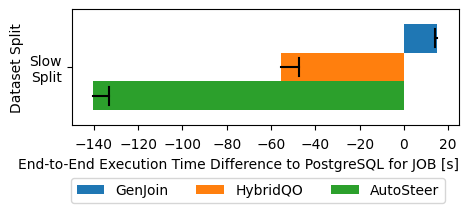

In [121]:
methods = ['GenJoin', 'HybridQO', 'AutoSteer']
workload = 'join_order_benchmark'
do_slow = True
do_inference = True
min_x = -150
max_x = 25


base_experiments = get_base_experiments(slow=do_slow)
experiment_labels = get_exeriment_labels(slow=do_slow)
plot_colors = np.array(list(mcolors.TABLEAU_COLORS.keys()))
bar_height = (1/(len(methods)+1))
time_attribute = 'total_time' if do_inference else 'total_no_inference'

fig, ax = plt.subplots(figsize=(5, 1.5))

execution_handles = []
for mi, method in enumerate(methods):
    df_method = get_method_data_with_differences(method, workload, time_attribute, do_slow=do_slow)

    bar_pos = np.arange(len(base_experiments)) + ((len(methods)/2) * bar_height) - (mi * bar_height) - bar_height
    bar_color = plot_colors[mi]

    execution_data = np.array([df_method.loc[df_method['base_experiment']==e,f'{time_attribute}.diff'].item() for e in base_experiments])
    execution_ci = np.array([df_method.loc[df_method['base_experiment']==e,f'{time_attribute}.ci'].item() for e in base_experiments])

    # COMMENT HERE: fake one-sided error bars
    ax.plot([execution_data-execution_ci, execution_data], [bar_pos + bar_height/2, bar_pos + bar_height/2], color='black')
    ax.plot([execution_data-execution_ci, execution_data-execution_ci], [bar_pos+0.05, bar_pos + bar_height-0.05], color='black')

    barh = ax.barh(bar_pos, execution_data, capsize=5, height=(1/(len(methods)+1)), align='edge', color=bar_color, label=method)

    # COMMENT HERE: original error bars
    # xerr = np.concatenate([
    #     [x if x >= 0 else 0 for x in execution_ci ],
    #     [np.abs(x) if x < 0 else 0 for x in execution_ci ]
    # ]).reshape(2, -1)
    # barh = ax.barh(bar_pos, execution_data, xerr=xerr, capsize=5, height=(1/(len(methods)+1)), align='edge', color=bar_color, label=method)

    execution_handles.append(barh)

ax.set_yticklabels(experiment_labels)
ax.set_yticks(np.array(bar_pos) + bar_height * len(methods)/2)
ax.tick_params(axis='x', pad=5.8)


if max_x is None:
    max_x = np.max(ax.get_xlim())
if min_x is None:
    min_x = np.min(ax.get_xlim())
ax.set_xlim([min_x, max_x])


ax.set_ylim([-0.5, len(base_experiments)-0.5])

ax.set_ylabel('Dataset Split')

if do_inference:
    execution_time_label = 'End-to-End Execution Time'
else:
    execution_time_label = 'Planning and Execution Time'
ax.set_xlabel(f'{execution_time_label} Difference to PostgreSQL for {WORKLOADS[workload]} [s]', loc='right')

ax.legend(execution_handles, methods, bbox_to_anchor=(0.48, -0.4), ncol=3, loc='upper center')

plt.subplots_adjust(wspace=.6)
# plt.title(f"Execution Time Difference for '{WORKLOADS[workload]}' Workload\n(With{'' if do_inference else 'out'} Inference Time)")
plt.savefig(f"figures/fig__{workload}_{'inference' if do_inference else 'no_inference'}{'_slow' if do_slow else ''}.png", bbox_inches='tight')
plt.show()

### STACK-Slow with Inference

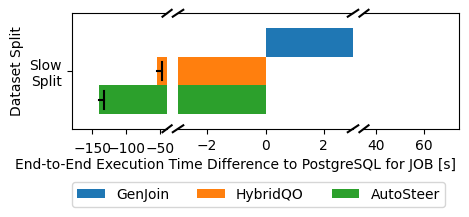

In [118]:
methods = ['GenJoin', 'HybridQO', 'AutoSteer']
do_inference = True
do_slow = True
min_x = -3
max_x = 3
left_x_min = -180
left_x_max = -40
right_x_min = 35
right_x_max = 75

base_experiments = get_base_experiments(slow=do_slow)
experiment_labels = get_exeriment_labels(slow=do_slow)
plot_colors = np.array(list(mcolors.TABLEAU_COLORS.keys()))
bar_height = (1/(len(methods)+1))
time_attribute = 'total_time' if do_inference else 'total_no_inference'

plt.figure(figsize=(5, 1.5))

ax_left = plt.subplot2grid((1, 15), (0, 0), colspan=4, rowspan=1)
ax_mid = plt.subplot2grid((1, 15), (0, 4), colspan=7, rowspan=1)
ax_right = plt.subplot2grid((1, 15), (0, 11), colspan=4, rowspan=1) 

execution_handles = []
for mi, method in enumerate(methods):
    df_method = get_method_data_with_differences(method, workload, time_attribute, do_slow=do_slow)

    bar_pos = np.arange(len(base_experiments)) + ((len(methods)/2) * bar_height) - (mi * bar_height) - bar_height
    bar_color = plot_colors[mi]

    execution_data = np.array([df_method.loc[df_method['base_experiment']==e,f'{time_attribute}.diff'].item() for e in base_experiments])
    execution_ci = np.array([df_method.loc[df_method['base_experiment']==e,f'{time_attribute}.ci'].item() for e in base_experiments])

    ax_left.plot([execution_data-execution_ci, execution_data], [bar_pos + bar_height/2, bar_pos + bar_height/2], color='black')
    ax_left.plot([execution_data-execution_ci, execution_data-execution_ci], [bar_pos+0.05, bar_pos + bar_height-0.05], color='black')
    ax_mid.plot([execution_data-execution_ci, execution_data], [bar_pos + bar_height/2, bar_pos + bar_height/2], color='black')
    ax_mid.plot([execution_data-execution_ci, execution_data-execution_ci], [bar_pos+0.05, bar_pos + bar_height-0.05], color='black')
    ax_right.plot([execution_data-execution_ci, execution_data], [bar_pos + bar_height/2, bar_pos + bar_height/2], color='black')
    ax_right.plot([execution_data-execution_ci, execution_data-execution_ci], [bar_pos+0.05, bar_pos + bar_height-0.05], color='black')

    barh = ax_left.barh(bar_pos, execution_data, capsize=5, height=(1/(len(methods)+1)), align='edge', color=bar_color, label=method)
    _ = ax_mid.barh(bar_pos, execution_data, capsize=5, height=(1/(len(methods)+1)), align='edge', color=bar_color, label=method)
    _ = ax_right.barh(bar_pos, execution_data, capsize=5, height=(1/(len(methods)+1)), align='edge', color=bar_color, label=method)
    execution_handles.append(barh)

ax_mid.set_yticks([])
ax_right.set_yticks([])

ax_left.spines['right'].set_visible(False)
ax_mid.spines['left'].set_visible(False)
ax_mid.spines['right'].set_visible(False)
ax_right.spines['left'].set_visible(False)

# Add the diagonal markings to show that the x-axis is broken
d = 0.03
left_tilt_factor = 1.6
kwargs = dict(transform=ax_left.transAxes, color='k', clip_on=False)
ax_left.plot((1-d*left_tilt_factor, 1+d*left_tilt_factor), (1-d, 1+d), **kwargs)
ax_left.plot((1-d*left_tilt_factor, 1+d*left_tilt_factor), (-d, +d), **kwargs)
kwargs.update(transform=ax_mid.transAxes)  # switch to the bottom axes
ax_mid.plot((-d, +d), (1-d, 1+d), **kwargs)
ax_mid.plot((-d, +d), (-d, +d), **kwargs)
ax_mid.plot((1-d, 1+d), (1-d, 1+d), **kwargs)
ax_mid.plot((1-d, 1+d), (-d, +d), **kwargs)
kwargs.update(transform=ax_right.transAxes)  # switch to the bottom axes
ax_right.plot((-d*left_tilt_factor, +d*left_tilt_factor), (1-d, 1+d), **kwargs)
ax_right.plot((-d*left_tilt_factor, +d*left_tilt_factor), (-d, +d), **kwargs)

ax_left.set_ylabel('Dataset Split')
ax_left.set_yticklabels(experiment_labels)
ax_left.set_yticks(np.array(bar_pos) + bar_height * len(methods)/2)
ax_left.tick_params(axis='x', pad=5.8)

ax_left.set_xlim([left_x_min, left_x_max])

if max_x is None:
    max_x = np.max(ax_right.get_xlim())
if min_x is None:
    min_x = np.min(ax_right.get_xlim())
ax_mid.set_xlim([min_x, max_x])
ax_right.set_xlim([right_x_min, right_x_max])


ax_left.set_ylim([-0.5, len(base_experiments)-0.5])
ax_mid.set_ylim([-0.5, len(base_experiments)-0.5])
ax_right.set_ylim([-0.5, len(base_experiments)-0.5])


if do_inference:
    execution_time_label = 'End-to-End Execution Time'
else:
    execution_time_label = 'Planning and Execution Time'
    
ax_mid.set_xlabel(f'{execution_time_label} Difference to PostgreSQL for {WORKLOADS[workload]} [s]', x=0.33)

ax_mid.legend(execution_handles, methods, bbox_to_anchor=(0.46, -0.4), ncol=3, loc='upper center')

plt.subplots_adjust(wspace=.7)
# plt.title(f"Execution Time Difference for '{WORKLOADS[workload]}' Workload\n(With{'' if do_inference else 'out'} Inference Time)")
plt.savefig(f"figures/fig__{workload}_{'inference' if do_inference else 'no_inference'}{'_slow' if do_slow else ''}.png", bbox_inches='tight')
plt.show()